<h1><center>Supervised ML Regression Competition</center></h1>


<img align="center" src="https://compraracciones.com/wp-content/uploads/2021/04/insurance.jpg" style="height:200px" style="width:100px"/>

<hr style="border:2px solid pink"> </hr>

You have been assigned the task of building a model that will predict the insurance cost

You'll find the data in the csv file `insurance`


- target col: "charges"


<hr style="border:2px solid pink"> </hr>


**Guidelines:** 


- train_test_split
    - random state = 42
    - test size = 0.3


- The one who gets the highest r2-score on test data wins


In [1]:
import pandas as pd
import numpy as np

## 1. Initial Data Exploration

Let's start by loading our dataset and taking a first look at it.


In [3]:
data = pd.read_csv('insurance.csv')

df = data.copy()
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,7725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Checking for Missing Values

It's important to know if our data has any missing values. Let's check that next.


In [5]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [ ]:
# data has no missing values


## 3. Descriptive Statistics

Now, let's move on to some descriptive statistics.

Understanding the distribution of our data is crucial. Let's calculate some descriptive statistics.


In [7]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,15799.570247
std,14.049960,6.098187,1.205493,12559.984021
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,8106.480000
50%,39.000000,30.400000,1.000000,12403.585225
75%,51.000000,34.693750,2.000000,18948.612903
max,64.000000,53.130000,5.000000,64571.074480


In [ ]:
# chrages has a mean of 15.8K which is above the median of 12.4K, which means the distribution is right-skewed

## 4. Distribution Analysis

Visualizing the distributions of our features can provide valuable insights. Let's plot the distributions for 'age', 'bmi', and 'charges'.

### Task:
- Plot the histogram for 'age'
- Plot the histogram for 'bmi'
- Plot the histogram for 'charges'


In [8]:
import matplotlib.pyplot as plt

In [ ]:
# Creating a function for creating the histograms, instead of repeating the process
def plot_hist(df, col_name):
    plt.hist(df[col_name], bins = 'auto', edgecolor='white')
    plt.xlabel(col_name)
    plt.ylabel('Count')
    plt.title(f'Histogram for {col_name}')
    plt.show()

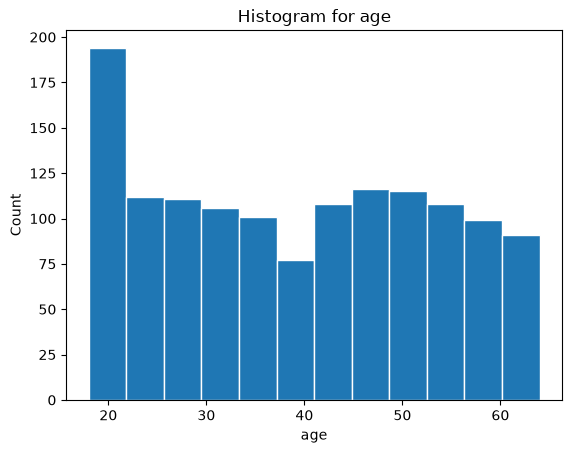

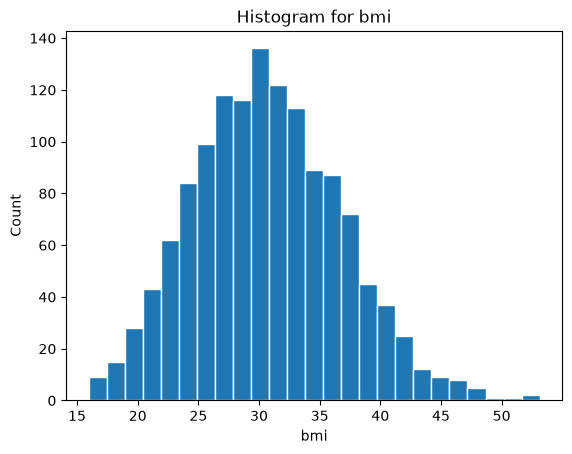

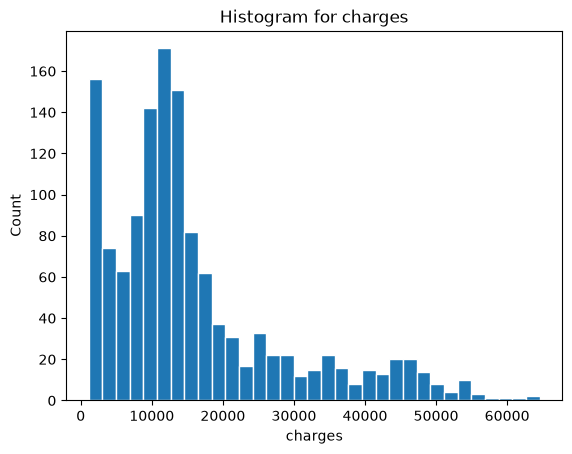

In [41]:
plot_hist(df, 'age')
plot_hist(df, 'bmi')
plot_hist(df, 'charges')

In [ ]:
# Distribution for age is roughly unifrorm with the highest peak around age 20
# bmi seems to be following an overall normal distribution, centered around 30
# charges is mostly right-skewed with a long tail of very expensive charges

## 5. Relationship Between Variables

Let's explore the relationship between some of our features and the target variable 'charges'. We'll create scatter plots to visualize these relationships.

### Task:
- Create a scatter plot for 'age' vs 'charges'
- Create a scatter plot for 'bmi' vs 'charges'
- Create a scatter plot for 'children' vs 'charges'


In [43]:
#Creating a function to create the scatter plots not to repeat processes
def plot_scatter(df, col_1, col_2):
    plt.scatter(df[col_1],df[col_2], alpha=0.6)
    plt.xlabel(col_1)
    plt.ylabel(col_2)
    plt.title(f'Scatter plot: {col_1} vs. {col_2}')
    plt.show()

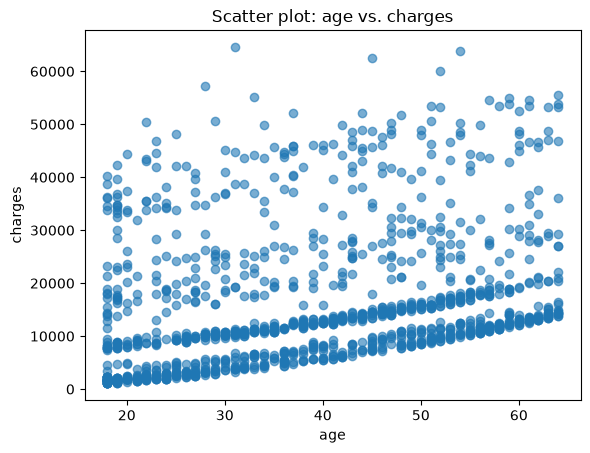

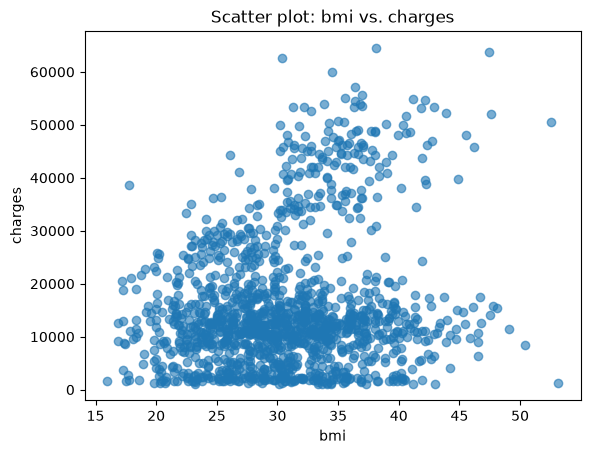

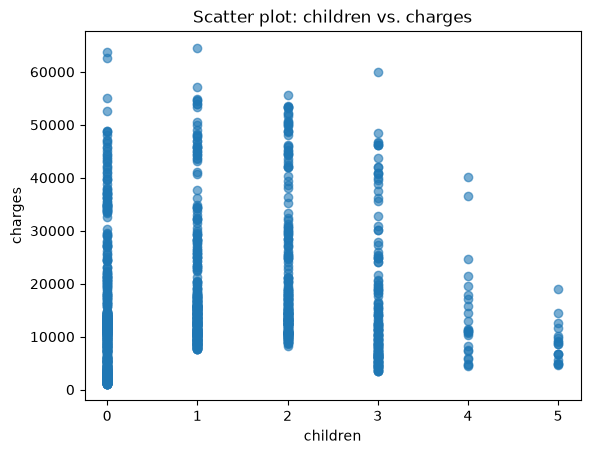

In [44]:
plot_scatter(df, 'age', 'charges')
plot_scatter(df, 'bmi', 'charges')
plot_scatter(df, 'children', 'charges')

In [ ]:
# Age vs. charges scatter plot noticable shows three different bands of charges rising with age

## 6. Categorical Analysis

Let's analyze the categorical features 'sex', 'smoker', and 'region' to see how they relate to 'charges'.

### Task:
- Plot the distribution of 'charges' for different 'sex'
- Plot the distribution of 'charges' for different 'smoker'
- Plot the distribution of 'charges' for different 'region'


In [46]:
import seaborn as sns

In [48]:
def plot_box(df, col, target='charges'):
    sns.boxplot(data = df, x = col, y = target)
    plt.title(f'{target} by {col}')
    plt.show()

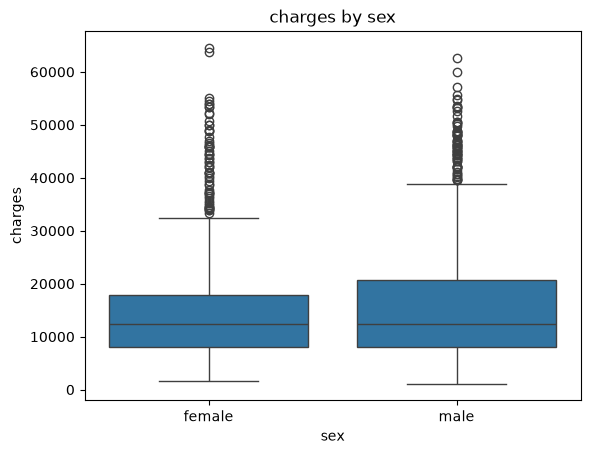

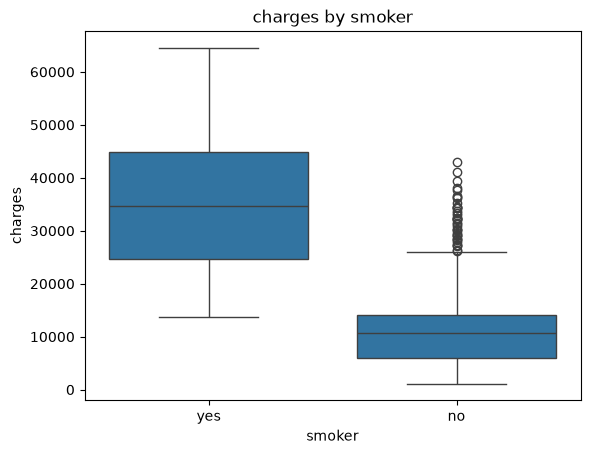

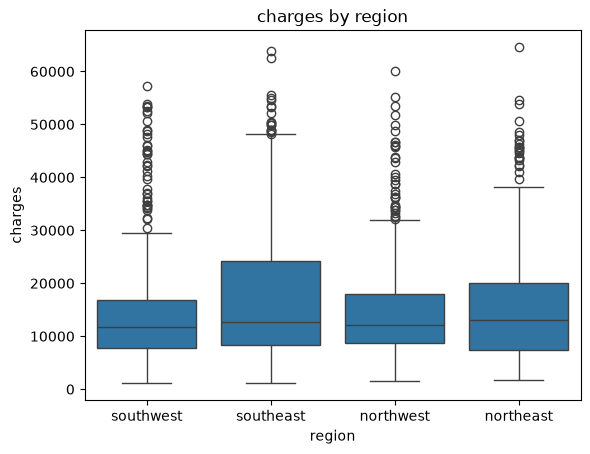

In [49]:
plot_box(df, 'sex')
plot_box(df, 'smoker')
plot_box(df, 'region')

In [50]:
# From the boxplots above, charges by region and sex are fairly similar between each other. 
# The difference in charges is highly noticable for the charges by smoker. From here we can see that the chrages for a smoker are significantly higher than non-smokers.

## 7. Correlation Analysis

To understand how our numerical features relate to each other and to the target variable, let's calculate and visualize the correlation matrix.

### Task:
- Calculate the correlation matrix for the dataset
- Visualize the correlation matrix using a heatmap


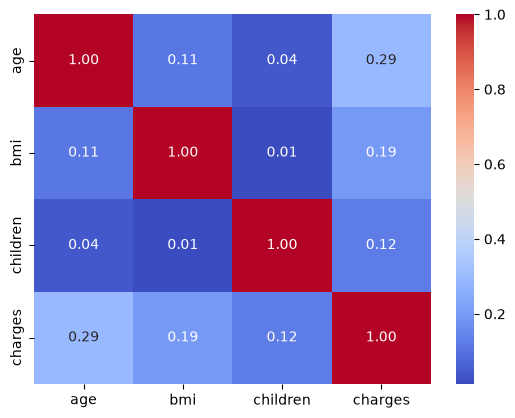

In [51]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

In [52]:
# From the heatmap we can notice that there is not a strong correlation between the numrical variables

# Modelling time!

## 1. Find the Naive Baseline

Before we build any models, let's establish a naive baseline. This will help us understand how well our models perform compared to a simple approach. In regression problems, the naive baseline is often the mean of the target variable.

### Task:
- Calculate the mean of the target variable 'charges'
- Explain why it's important to establish a naive baseline


In [61]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

In [62]:
X = df.drop(columns=['charges'])
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

baseline_pred = np.full(len(y_test), y_train.mean())
print("Baseline R^2:  ", r2_score(y_test, baseline_pred))
print("Baseline RMSE:", root_mean_squared_error(y_test, baseline_pred))

Baseline R^2:   -0.0006018247692027856
Baseline RMSE: 12541.030897590255


In [57]:
# Establishing a naive baseline is imporant as this is the score we get with the simplest model.
# Any other model we create must surpass the baseline in order to be useful.

## 2. Initial Modelling Without GridSearch or Pipeline

Let's build a simple linear regression model without any feature engineering, grid search, or pipeline. This will serve as our initial baseline for comparison.

### Task:
- Split the data into training and test sets, using the guidelines at the top (`test_size=0.3`, `random_state=42`)
- Encode the text columns `sex`, `smoker` and `region` first: a model only accepts numbers. `pd.get_dummies(..., drop_first=True)` is enough here
- Train a simple linear regression model
- Evaluate its performance using regression metrics
- Write it down as a markdown below so you can keep track. This is a scientific experiment


In [58]:
from sklearn.linear_model import LinearRegression

In [63]:
X_enc = pd.get_dummies(X, drop_first=True)
X_train_e, X_test_e, y_train, y_test = train_test_split(X_enc, y, test_size=0.3, random_state=42)

lr = LinearRegression()
lr.fit(X_train_e, y_train)

y_pred = lr.predict(X_test_e)
print(f"R^2: {r2_score(y_test, y_pred)}, RMSE: {root_mean_squared_error(y_test, y_pred)}, MAE: {mean_absolute_error(y_test, y_pred)}")

R^2: 0.7263438163107672, RMSE: 6558.510612530447, MAE: 4996.264726691542


Linear Regression Evaluation Metrics:
+ R^2: 0.73
+ RMSE: 6558.51
+ MAE: 4996.26

## 3. Feature Engineering

Now, let's brainstorm and create some new features to see if we can improve the model's performance.

### Questions:
1. Should we create an interaction feature between 'bmi' and 'children'? 
2. Should we create age groups to see if the model improves by categorizing age?
3. Should we create a high-risk indicator based on 'smoker' and 'bmi'?

- Remember nothing is set in stone, this is your experiment, your hypothesis. You may not need to, but its important to explore these questions

### Task:
- Create new features based on the questions above
- Explain the rationale behind each feature



In [64]:
df_fe = df.copy()
df_fe['is_smoker'] = (df_fe['smoker'] == 'yes').astype(int)
df_fe['obese'] = (df_fe['bmi'] >= 30).astype(int)
df_fe['high_risk'] = df_fe['is_smoker'] * df_fe['obese'] 
df_fe['age_group'] = pd.cut(df_fe['age'], bins=[17, 30, 45, 64], labels=['young', 'middle', 'senior'])

+ Chanage smoker to a numerical value 0/1.
+ bmi column by itself is not very useful, so we define a threshold of 30 as the medical standard cutoff. 1: bmi above 30, 2: bmi below 30.
+ High-risk: smoker + BMI > 30
+ Age groups: defining age groups


## 4. Modelling with Feature Engineering

Now that we have new features, let's see if they improve our model's performance.
Did it improve the performance? Yes? No? Why

### Task:
- Split the data into training and test sets
- Train a linear regression model with the new features
- Evaluate its performance using regression metrics


In [65]:
X_fe = pd.get_dummies(df_fe.drop(columns=['charges']), drop_first=True)
y_fe = df_fe['charges']

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(X_fe, y_fe, test_size=0.3, random_state=42)

lr_fe = LinearRegression()
lr_fe.fit(X_train_fe, y_train_fe)
y_pred_fe = lr_fe.predict(X_test_fe)
print(f"R^2:  ", round(r2_score(y_test_fe, y_pred_fe), 3))
print("RMSE:", round(root_mean_squared_error(y_test_fe, y_pred_fe), 3))
print("MAE: ", round(mean_absolute_error(y_test_fe, y_pred_fe), 3))

R^2:   0.82
RMSE: 5317.041
MAE:  3795.141


The R^2 score increased from 0.72 to 0.82. A linear model can only add up each feature’s effect separately and in straight lines. The new features let it capture combinations, such as smoking together with high BMI, and different effects for different age ranges. The high-risk indicator is the most likely cause of the improvement, since it combines two health risks the model couldn’t link before.

## 5. Modelling with Pipeline and Grid Search

Now, let's see how using pipelines can simplify our workflow and prevent data leakage. We'll also use GridSearchCV to find the best hyperparameters.

### Task:
- Create a pipeline that starts from the raw columns: a `ColumnTransformer` that one-hot encodes the text columns and scales the numeric ones, followed by a `Ridge` regression
- Plain `LinearRegression` has no hyperparameter worth tuning; `Ridge` has `alpha`, the strength of its regularisation. Define a grid of `alpha` values (for example from 0.01 to 100)
- Use `GridSearchCV` on the training set to find the best `alpha`, then evaluate the best model on the test set once


In [73]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [93]:
X_p = df_fe.drop(columns='charges')
y_p = df_fe['charges']

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_p, y_p, test_size=0.3, random_state=42)

num_cols = ['age', 'bmi', 'children', 'is_smoker', 'obese', 'high_risk']
cat_cols = ['sex', 'region', 'age_group']

preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),
    ('num', StandardScaler(), num_cols),
])

In [94]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

In [95]:
pipe = Pipeline([
    ('pre', preprocessor),
    ('model', Ridge())
])

In [96]:
from sklearn.model_selection import GridSearchCV

In [102]:
param_grid = {'model__alpha': [0.01, 0.1, 1, 10, 100]}

grid = GridSearchCV(pipe, param_grid, cv=5, scoring='r2')
grid.fit(X_train_p, y_train_p)

print("Best alpha:", grid.best_params_)
print("Best CV R^2:", round(grid.best_score_, 3))

Best alpha: {'model__alpha': 10}
Best CV R^2: 0.802


In [98]:
best_model = grid.best_estimator_
pred = best_model.predict(X_test_p)

print("Test R^2:  ", round(r2_score(y_test_p, pred), 3))
print("Test RMSE:", round(root_mean_squared_error(y_test_p, pred)))

Test R^2:   0.821
Test RMSE: 5308


## 6. Trying Another Model with Pipeline

Let's try a model that can capture non-linear patterns, such as the smoker and BMI interaction you may have spotted.

### Task:
- Create a pipeline with the same preprocessing and a `KNeighborsRegressor` (tune `n_neighbors`) or a `DecisionTreeRegressor` (tune `max_depth` and `min_samples_leaf`)
- Define a parameter grid for grid search
- Use GridSearchCV to find the best parameters and evaluate the model

Tomorrow's lesson introduces ensembles. Come back afterwards and try `RandomForestRegressor` and `GradientBoostingRegressor` in the same pipeline: they usually win this challenge.

In [85]:
from sklearn.tree import DecisionTreeRegressor

In [99]:
pipe_tree = Pipeline([
    ('pre', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42)),
])

In [100]:
param_grid_tree = {
    'model__max_depth': [3, 4, 5, 6, 8, 10],
    'model__min_samples_leaf': [1, 5, 10, 20],
}

grid_tree = GridSearchCV(pipe_tree, param_grid_tree, cv=5, scoring='r2')
grid_tree.fit(X_train_p, y_train_p)

print("Best params:", grid_tree.best_params_)
print("Best CV R^2:", round(grid_tree.best_score_, 3))

Best params: {'model__max_depth': 6, 'model__min_samples_leaf': 5}
Best CV R^2: 0.832


In [103]:
pred_tree = grid_tree.best_estimator_.predict(X_test_p)

print("Test R^2:  ", round(r2_score(y_test_p, pred_tree), 3))
print("Test RMSE:", round(root_mean_squared_error(y_test_p, pred_tree)))

Test R^2:   0.856
Test RMSE: 4756


I used a decision tree because it can learn non-linear patterns and combinations of features by itself. The grid search chose max_depth = 6 and min_samples_leaf = 5. The R^2 cross-validation was 0.832 and the test R^2 0.856, with an RMSE of 4756.

This beats linear regression with engineered features (R^2 0.82) and Ridge (R^2 0.80). A tree splits the data into groups and gives each group its own prediction, so it can treat combinations, such as smokers with a high BMI, differently from the rest. A linear model can only add effects together.

The CV and test scores are close, which suggests the tree isn’t overfitting. Limiting the depth and leaf size kept it from memorising the training data.

## 7. GridSearch with Several Models

Finally, let's compare several models using GridSearchCV to find the best one.

### Task:
- Define multiple models and their parameter grids
- Use GridSearchCV to find the best model and parameters

*Hint:* `GridSearchCV` accepts a list of grids, and the model step itself can be one of the parameters:

```python
param_grid = [
    {"model": [Ridge()], "model__alpha": [0.1, 1, 10]},
    {"model": [DecisionTreeRegressor(random_state=42)], "model__max_depth": [3, 5, 8]},
]
```

In [104]:
pipe_all = Pipeline([
    ('pre', preprocessor),
    ('model', Ridge()),
])

In [105]:
from sklearn.neighbors import KNeighborsRegressor

In [106]:
param_grid_all = [
    {'model': [Ridge()],
     'model__alpha': [0.01, 0.1, 1, 10, 100]},

    {'model': [DecisionTreeRegressor(random_state=42)],
     'model__max_depth': [3, 4, 5, 6, 8],
     'model__min_samples_leaf': [1, 5, 10, 20]},

    {'model': [KNeighborsRegressor()],
     'model__n_neighbors': [3, 5, 7, 10, 15, 20]},
]

In [107]:
grid_all = GridSearchCV(pipe_all, param_grid_all, cv=5, scoring='r2')
grid_all.fit(X_train_p, y_train_p)

print("Best model and params:", grid_all.best_params_)
print("Best CV R^2:", round(grid_all.best_score_, 3))

Best model and params: {'model': DecisionTreeRegressor(random_state=42), 'model__max_depth': 6, 'model__min_samples_leaf': 5}
Best CV R^2: 0.832


In [108]:
results = pd.DataFrame(grid_all.cv_results_)
results['model_name'] = results['param_model'].astype(str).str.split('(').str[0]
results.groupby('model_name')['mean_test_score'].max().sort_values(ascending=False)

model_name
DecisionTreeRegressor    0.832134
KNeighborsRegressor      0.826953
Ridge                    0.802380
Name: mean_test_score, dtype: float64

In [110]:
y_pred_final = grid_all.best_estimator_.predict(X_test_p)

print("Test R^2:  ", round(r2_score(y_test_p,y_pred_final), 3))
print("Test RMSE:", round(root_mean_squared_error(y_test_p, y_pred_final)))

Test R^2:   0.856
Test RMSE: 4756


I compared Ridge, a decision tree and KNN in one grid search, each with its own settings. The best R^2 cross-validation for each model was: Ridge 0.80, decision tree 0.83, KNN 0.82.

The best overall was the decision tree with max_depth = 6 and min_samples_leaf = 5, giving a test R^2 of 0.856 and an RMSE of 4756. This is the same model and result as in step 6, which confirms the earlier search.

# Machine Learning: Master Challenge

## 8. Calculating Potential Cost or Loss

### Challenge:
Now that you've built and optimized your models, it's time for the final challenge! Your task is to minimize the Root Mean Squared Error (RMSE) of your model's predictions and calculate the potential financial impact of your model's errors.

### Task:
1. Calculate the RMSE of your final model's predictions.
2. Break down the errors into underestimation and overestimation.
3. Calculate the total potential cost or loss to the company.
4. Compete with your classmates to see who can achieve the lowest RMSE and financial impact!

### Explanation:
The RMSE provides an estimate of the average error in your model's predictions. We will also analyze the errors by categorizing them into underestimations and overestimations to understand their financial impact.

#### Steps to Calculate Underestimation and Overestimation Errors:

1. **Calculate RMSE**:
   - Use the `mean_squared_error` function from `sklearn.metrics` and pass your actual values (`y_test`) and predicted values (`y_pred_final`) to it.
   - Take the square root of the result to get the RMSE, or use `root_mean_squared_error` directly.
   
2. **Calculate Underestimation Error**:
   - Identify the instances where the actual charges (`y_test`) are greater than the predicted charges (`y_pred_final`).
   - For these instances, calculate the difference between the actual and predicted charges.
   - Sum these differences to get the total underestimation error.

3. **Calculate Overestimation Error**:
   - Identify the instances where the actual charges (`y_test`) are less than the predicted charges (`y_pred_final`).
   - For these instances, calculate the difference between the predicted and actual charges.
   - Sum these differences to get the total overestimation error.

4. **Calculate Total Potential Cost or Loss**:
   - Add the total underestimation error and the total overestimation error to get the total potential cost or loss. This is the sum of the absolute errors, so it is the MAE multiplied by the number of test rows.

### Let's see who can build the best model!

#### Detailed Instructions:

1. **Calculate RMSE**:
   - Use `mean_squared_error` with `y_test` and `y_pred_final`.
   - Use `np.sqrt` to take the square root of the result.

2. **Calculate Underestimation Error**:
   - Use a boolean condition to filter `y_test` values that are greater than `y_pred_final`.
   - Subtract the predicted values from the actual values for these instances.
   - Sum these differences.

3. **Calculate Overestimation Error**:
   - Use a boolean condition to filter `y_test` values that are less than `y_pred_final`.
   - Subtract the actual values from the predicted values for these instances.
   - Sum these differences.

4. **Calculate Total Potential Cost or Loss**:
   - Add the results of the underestimation error and overestimation error to get the total potential cost or loss.

### Example Walkthrough:

1. **Calculate RMSE**:
   - `rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))`
   - This gives you the average prediction error in dollars.

2. **Calculate Underestimation Error**:
   - `underestimation_error = np.sum(y_test[y_test > y_pred_final] - y_pred_final[y_test > y_pred_final])`
   - This gives you the total amount by which the model undercharged.

3. **Calculate Overestimation Error**:
   - `overestimation_error = np.sum(y_pred_final[y_test < y_pred_final] - y_test[y_test < y_pred_final])`
   - This gives you the total amount by which the model overcharged.

4. **Calculate Total Potential Cost or Loss**:
   - `total_potential_loss = underestimation_error + overestimation_error`
   - This gives you the total financial impact of the model's errors.

### Leaderboard:
Post your RMSE score and total potential cost or loss on the class leaderboard. The student with the lowest RMSE and total potential cost or loss wins bragging rights

### Post Your Results 

- Name
- Model Type
- RMSE
- Underestimation Error
- Overestimation Error
- Total Potential Cost/Loss

In [111]:
from sklearn.metrics import mean_squared_error

In [112]:
# 1. Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test_p, y_pred_final))
print("RMSE:", round(rmse))

RMSE: 4756


In [113]:
y_true = y_test_p.to_numpy()

In [115]:
# 2. Calculate Underestimation Error
under = y_true > y_pred_final   # condition that model predicted too low

underestimation_error = np.sum(y_true[under] - y_pred_final[under])
print(f"Underestimation error: {underestimation_error:.0f}")

Underestimation error: 493753


In [120]:
# 3. Calculate Overestimation Error
over = y_true < y_pred_final

overestimation_error = np.sum(y_pred_final[over] - y_true[over])
print(f"Overestimation error: {overestimation_error:.0f}")

Overestimation error: 615594


In [121]:
# 4. Total potential loss

total_loss = underestimation_error + overestimation_error
print(f"Total potential loss:  {total_loss:.0f}")

Total potential loss:  1109346


In [122]:
print(f"Check: {mean_absolute_error(y_true, y_pred_final) * len(y_true):.0f}")

Check: 1109346


+ Name: Jovana
+ Model type: Decision tree (max_depth = 6, min_samples_leaf = 5), with engineered features
+ RMSE: 4756
+ Underestimation error: 493753
+ Overestimation error: 615594
+ Total potential cost/loss: 1109346

## Conclusion

Congratulations! You've completed the lab. Here's a summary of what we've covered:
1. Established a naive baseline using the mean of the target variable.
2. Built an initial linear regression model without any feature engineering or optimization.
3. Performed feature engineering to create new, potentially useful features.
4. Used pipelines and GridSearchCV to optimize the model.
5. Evaluated the final model's performance using RMSE to understand its business impact.

By following these steps, you now have a robust understanding of how to approach a regression problem, from initial exploration to model optimization and business impact assessment. Great job!
